## 01. Abstract

**Air-Travel-to-Accommodation — U.S. Lodging Demand, retrospective macro-factor falsification (26 October 2026).** Does airline passenger activity, known with a conservative reporting delay, improve three-month-ahead U.S. accommodation-payroll YoY forecasts beyond lodging persistence and restaurant payroll growth? Using three frozen government series (2014-01 to 2026-09, with airline data through 2026-06), we obtain **82** purged expanding-window forecasts. The factor improves a bounded-macro Ridge challenger relative to its own controls, but fails a simple historical mean: **full RMSE 35.015 pp vs controls 46.313 pp vs mean 22.937 pp**. A 12-month block-shuffle is exploratory, and the bootstrap interval straddles zero. **Verdict: no stable predictive superiority, no publication-vintage validation, and no equity alpha.**

In [1]:
import json, hashlib, math
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from run_analysis import read_data, panel_from, walk_forward, score, block_bootstrap, run
get_ipython().run_line_magic('matplotlib','inline')
print('US travel/accommodation research — fixed October 2026 snapshot, NOT PIT or equity alpha')

US travel/accommodation research — fixed October 2026 snapshot, NOT PIT or equity alpha


In [2]:
report=json.loads(Path('results/metrics.json').read_text())
raw=read_data();panel=panel_from(raw);oos=walk_forward(panel)
placebo=pd.read_csv('results/block_placebo_null.csv').null_delta_rmse.to_numpy()
boot=pd.read_csv('results/bootstrap_deltas.csv').bootstrap_delta_rmse.to_numpy()
weights=pd.read_csv('results/exposure_sensitivity.csv')
print('Source months:',len(raw),'formation rows:',len(panel),'freshly recomputed OOS origins:',len(oos))
print('Loaded recorded 1,000 block-shuffle refits, 2,000 bootstrap draws, 1,000 exposure perturbations from run_analysis.py')

Source months: 153 formation rows: 122 freshly recomputed OOS origins: 82
Loaded recorded 1,000 block-shuffle refits, 2,000 bootstrap draws, 1,000 exposure perturbations from run_analysis.py


## 02. Research Design & Hypotheses

**Primary question:** can U.S. air revenue passenger miles growth at formation month *t*, measured through *t−4*, predict accommodation payroll YoY growth at *t+3* after controlling for the lodging and restaurant cycles?

- **H1 (economic transmission):** passenger-mile growth can lead overnight stays, hotel room demand and eventual staffing adjustments; airline travel is an imperfect mix of business, leisure and connecting trips.
- **H2 (incremental prediction):** a fixed-scale air-minus-restaurant demand gap reduces purged expanding-window OOS RMSE relative to the *same* multivariate model without it.
- **H3 (robustness):** any apparent gain should survive the 2020 disruption, alternative horizons and delays, year exclusions, exposure-weight perturbations and block-aware null comparisons.

**Null / failure rule:** if the full model fails the historical mean or persistence benchmark, or its advantage is regime-dependent and unverified for historical releases, it is **not** a validated lead factor. A positive association does not imply causation or a tradable equity return.

In [3]:
print('Fixed primary horizon=3 months; BTS lag=4 months; CES lag=2 months; Ridge alpha=10')
print('Null: fails any simple benchmark or regime/PIT robustness gate -> not validated')

Fixed primary horizon=3 months; BTS lag=4 months; CES lag=2 months; Ridge alpha=10
Null: fails any simple benchmark or regime/PIT robustness gate -> not validated


In [4]:
display(pd.DataFrame({'hypothesis':['H1','H2','H3'],'test':['air travel leads hotel payroll','incremental OOS RMSE vs controls','horizons, lag, block null, regime']}).set_index('hypothesis'))

,test
hypothesis,
H1,air travel leads hotel payroll
H2,incremental OOS RMSE vs controls
H3,"horizons, lag, block null, regime"


## 03. Industry Context

The U.S. accommodation segment employs workers in hotels, motels and other lodging; travel can influence staffing, but room-night demand is not observed directly here. BTS passenger miles cover U.S. air-carrier domestic and international services and do not isolate U.S. hotel stays or foreign carriers. In the frozen December observations, passenger miles rose **6.76%** from 2019 to 2025 while accommodation employment **fell 8.48%**; restaurant employment rose only **1.03%**. This divergence challenges any one-for-one staffing interpretation: hotel productivity, labor scarcity, short-term rentals, corporate travel mix and occupancy may break the link.

**Counterthesis:** airline demand may be contemporaneous with travel but too late or too noisy to forecast accommodation employment, especially during pandemic shutdowns and reopening. A structural recovery story cannot substitute for an incremental predictive test. No market-size or revenue-growth forecast is invented.

In [5]:
levels=raw.loc[['2019-12-01','2025-12-01'],['AIRRPMTSID11','CES7072100001','CES7072200001']]
display(pd.DataFrame({'2019-12':levels.iloc[0],'2025-12':levels.iloc[1],'change_pct':(levels.iloc[1]/levels.iloc[0]-1)*100}).round(3))

,2019-12,2025-12,change_pct
AIRRPMTSID11,90063718.0,96151050.0,6.759
CES7072100001,2118.2,1938.5,-8.484
CES7072200001,12217.9,12343.3,1.026


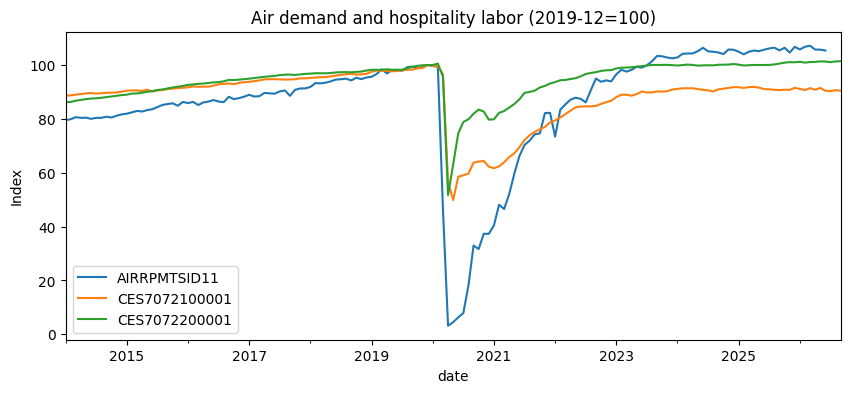

In [6]:
norm=raw[['AIRRPMTSID11','CES7072100001','CES7072200001']].div(raw.loc['2019-12-01',['AIRRPMTSID11','CES7072100001','CES7072200001']])*100
ax=norm.plot(figsize=(10,4),title='Air demand and hospitality labor (2019-12=100)');ax.set_ylabel('Index');plt.show()

## 04. Data & Source Integrity

Frozen monthly inputs: **153** dates, 150 air observations, 153 accommodation and restaurant observations. All three are A-grade federal statistical series displayed by FRED; this grade assesses source authority, **not** vintage completeness. The original display tables are: [BTS AIRRPMTSID11](https://fred.stlouisfed.org/data/AIRRPMTSID11), [BLS CES7072100001](https://fred.stlouisfed.org/data/CES7072100001) and [BLS CES7072200001](https://fred.stlouisfed.org/data/CES7072200001). Reported updates: air **2026-10-01**; both CES series **2026-10-02**. Units are respectively thousands of seasonally adjusted passenger-miles and thousands of seasonally adjusted employees.

The frozen CSV was **manually transcribed** from the official FRED table displays on 2026-10-26 because direct bulk downloading was unavailable. A separate transparent `build_frozen_inputs.py` preserves each source row, while `data/transcription_qa.md` records spot-checks and remaining transcription risk. Original historical release timestamps and vintage-specific values are **UNKNOWN**. See `data/source_register.csv` for source URL, unit, update date, revision policy, assumptions and permitted use.

In [7]:
source=pd.read_csv('data/source_register.csv')
display(source[['series_id','quality','units','last_updated_reported_by_FRED','historical_vintages_available']])

,series_id,quality,units,last_updated_reported_by_FRED,historical_vintages_available
0,AIRRPMTSID11,A,thousands of revenue passenger miles seasonall...,2026-10-01 09:01 CDT,NO
1,CES7072100001,A,thousands of employees seasonally adjusted,2026-10-02 08:26 CDT,NO
2,CES7072200001,A,thousands of employees seasonally adjusted,2026-10-02 08:26 CDT,NO


In [8]:
assert raw.index.is_unique and len(raw)==153
assert raw.AIRRPMTSID11.notna().sum()==150
assert raw.loc['2020-04-01','AIRRPMTSID11']==2877804
assert raw.loc['2020-04-01','CES7072100001']==1199.1
print('Spot-check QA passed; full source-to-source reconciliation NOT performed')

Spot-check QA passed; full source-to-source reconciliation NOT performed


## 05. Point-in-Time Availability

At origin *t*, BTS features are taken only from *t−4* or earlier and CES features only from *t−2* or earlier. These are **assumed conservative availability buffers**, not historical release-date proof. A target formed at *u* with horizon *h* is admitted to training at origin *t* only when **u+h+2 ≤ t**, leaving an extra CES reporting buffer. Train-only standardization is repeated at each origin; the hyperparameter alpha=10, factor scale=20 and OOS minimum training count=36 are fixed, not optimized on test performance.

**Critical limitation:** historical BTS and BLS data have been revised and seasonally adjusted; this October 2026 snapshot can leak future revisions into earlier formation periods. This is a **retrospective fixed-snapshot falsification**, not a historical point-in-time simulation. Neither lagging latest-revised observations nor purging labels repairs that issue.

In [9]:
display(panel[['accom_yoy_l2','food_yoy_l2','air_yoy_l4','travel_gap','target']].head(6).round(4))

,accom_yoy_l2,food_yoy_l2,air_yoy_l4,travel_gap,target
date,,,,,
2015-05-01,1.7087,3.0619,3.0111,-0.0025,-2.4933
2015-06-01,1.3353,3.0303,3.1365,0.0053,-2.2549
2015-07-01,1.5288,3.0319,2.8022,-0.0115,-1.8258
2015-08-01,0.6092,3.1307,2.8942,-0.0118,-2.0890
2015-09-01,1.3482,3.4426,3.4393,-0.0002,-2.2182
2015-10-01,1.2993,3.4688,4.3752,0.0453,-2.1888


In [10]:
origin=oos.index[20];train=panel.loc[panel.origin<=origin-pd.DateOffset(months=5)]
print('Origin',origin.date(),'last admissible training origin',train.index.max().date(),'training n',len(train))
assert train.index.max()<=origin-pd.DateOffset(months=5)

Origin 2020-05-01 last admissible training origin 2019-12-01 training n 56


## 06. Factor Construction

For monthly levels A (air miles), L (accommodation employment), and F (food-service employment), define log-YoY percentage growth:

`g_A(t) = 100 ln[A(t−4)/A(t−16)]`, `g_L(t) = 100 ln[L(t−2)/L(t−14)]`, `g_F(t) = 100 ln[F(t−2)/F(t−14)]`.

The **predefined travel-specific gap** is `S(t) = tanh((g_A(t) − g_F(t))/20)`. Both component weights are analyst hypotheses (1 and −1), not estimated historical company exposures. `tanh` caps the signal between −1 and +1; the 20-pp scale is fixed before evaluation. The control model uses bounded lodging/restaurant YoY transforms `tanh(g/20)` and a bounded lodging 3-month change `tanh(mom3/10)` to limit pandemic-era feature extrapolation.

The dependent variable is **Y(t,h)=100 ln[L(t+h)/L(t+h−12)]**, three-month-ahead lodging-employment YoY, in percentage points. This is neither lodging revenue nor a security return. No cross-sectional stock IC or long-short spread is calculated without issuer total returns.

In [11]:
display(pd.DataFrame({'feature':['air_yoy_l4','food_yoy_l2','travel_gap'],'formula':['100log(A[t-4]/A[t-16])','100log(F[t-2]/F[t-14])','tanh((air-food)/20)'],'lookahead':['no index future','no index future','fixed transform']}))

,feature,formula,lookahead
0,air_yoy_l4,100log(A[t-4]/A[t-16]),no index future
1,food_yoy_l2,100log(F[t-2]/F[t-14]),no index future
2,travel_gap,tanh((air-food)/20),fixed transform


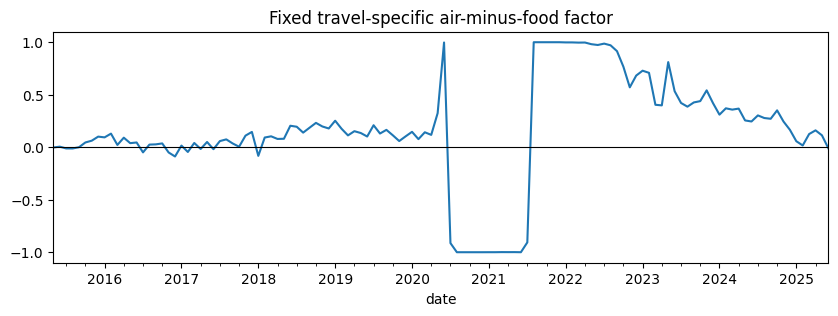

In [12]:
ax=panel['travel_gap'].plot(figsize=(10,3),title='Fixed travel-specific air-minus-food factor');ax.axhline(0,color='black',lw=.8);plt.show()

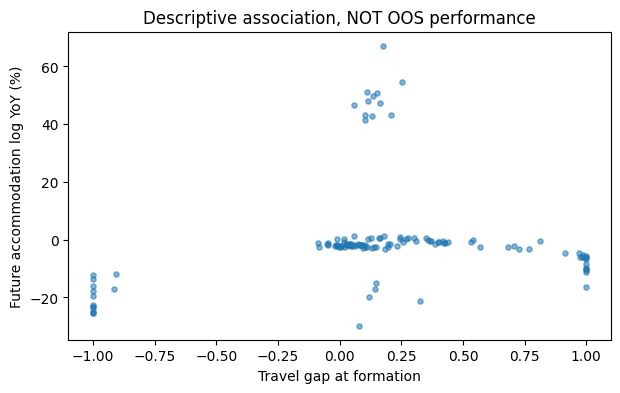

In [13]:
fig,ax=plt.subplots(figsize=(7,4));ax.scatter(panel.travel_gap,panel.target,s=14,alpha=.55);ax.set(xlabel='Travel gap at formation',ylabel='Future accommodation log YoY (%)',title='Descriptive association, NOT OOS performance');plt.show()

## 07. Exposure & Transmission

`data/exposure_map.csv` identifies the three observed subsectors: airline activity is an upstream travel proxy, accommodation employment is the independent sector outcome, and restaurant payrolls proxy a broader discretionary-services cycle. No historical company-level passenger exposure, hotel chain revenue shares, room nights or occupancy are available; **company exposure mapping and leave-one-company-out are NOT TESTED**. The analyst 1:1 growth weighting is stress-tested using 1,000 draws that change air weight between 0.75 and 1.25, with the restaurant comparator weight adjusted symmetrically.

In [14]:
display(pd.read_csv('data/exposure_map.csv'))

,segment,series,role,transmission,weight_basis,historical_company_exposure_known
0,Air travel demand,AIRRPMTSID11,Leading proxy,Air passenger activity may precede hotel room-...,Predefined equal-unit growth comparison only,NO
1,Accommodation employment,CES7072100001,Target,Payrolls reflect lodging labor demand and prod...,Observed sector outcome not issuer revenue,NO
2,Food services and drinking places,CES7072200001,Macro control,Restaurant staffing proxies broader discretion...,Predefined equal-unit growth comparison only,NO


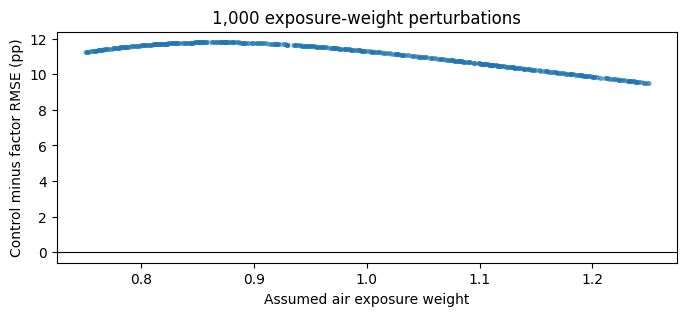

In [15]:
fig,ax=plt.subplots(figsize=(8,3));ax.scatter(weights.air_weight,weights.delta_rmse,s=7,alpha=.25);ax.axhline(0,color='black',lw=.8);ax.set(xlabel='Assumed air exposure weight',ylabel='Control minus factor RMSE (pp)',title='1,000 exposure-weight perturbations');plt.show()

## 08. Outcomes & Baselines

All 82 primary forecasts share the **same origins** (2018-09-01 to 2025-06-01). The models are: (1) training-target historical mean; (2) directly carried-forward lagged accommodation YoY; (3) Ridge(alpha=10) on bounded lodging YoY, restaurant YoY and lodging three-month momentum; (4) identical Ridge plus the fixed travel gap. Each regression fits only labels matured by the cutoff and scales its predictors using only its own training rows. The outcome is the future accommodation payroll YoY log change; no portfolio return, transaction costs or Sharpe ratio are asserted.

In [16]:
print('Same-origin forecasts:',len(oos),'from',oos.index.min().date(),'to',oos.index.max().date())
display(oos[['actual','mean','persistence','controls','full']].head().round(3))

Same-origin forecasts: 82 from 2018-09-01 to 2025-06-01


,actual,mean,persistence,controls,full
origin,,,,,
2018-09-01,-3.297,-1.963,1.779,-1.854,-2.173
2018-10-01,-2.208,-1.957,2.040,-1.731,-2.157
2018-11-01,-1.612,-1.947,2.225,-1.613,-1.832
2018-12-01,1.316,-1.958,1.808,-1.815,-2.018
2019-01-01,54.704,-1.970,1.542,-1.922,-2.257


In [17]:
scores=score(oos);display(pd.DataFrame(scores).T.round(3))
assert len(oos)==82

,rmse,mae
mean,22.937,14.963
persistence,26.029,20.344
controls,46.313,24.421
full,35.015,21.407


## 09. Empirical Findings

| Model | OOS RMSE (pp) | OOS MAE (pp) |
|:--|--:|--:|
| Historical mean | 22.937 | 14.963 |
| Accommodation persistence | 26.029 | 20.344 |
| Bounded macro controls | 46.313 | 24.421 |
| Controls + travel gap | 35.015 | 21.407 |

The factor reduces RMSE by **11.298 pp relative to its weak multivariate control**, but remains **12.078 pp worse than the historical mean**. A small p-like statistic from a null comparison must not override this baseline failure. Large pandemic-era target swings make fitted regressions unstable and dominate aggregate error. See `results/walk_forward_oos.csv`, `results/scorecard.csv` and computed charts.

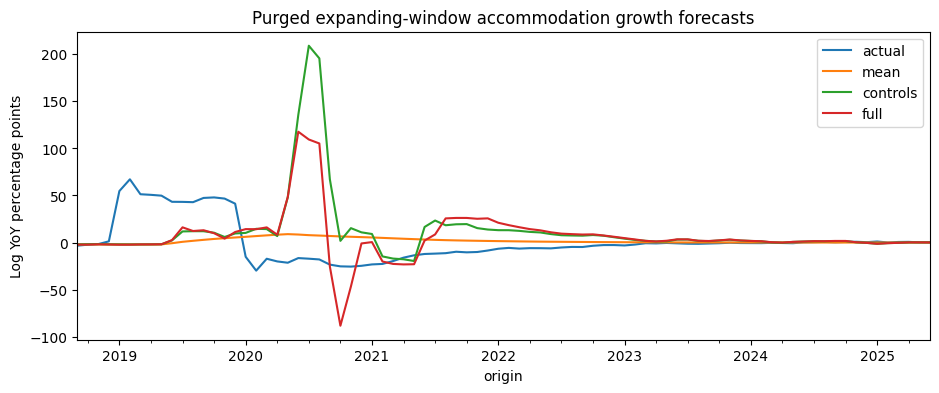

In [18]:
ax=oos[['actual','mean','controls','full']].plot(figsize=(11,4),title='Purged expanding-window accommodation growth forecasts');ax.set_ylabel('Log YoY percentage points');plt.show()

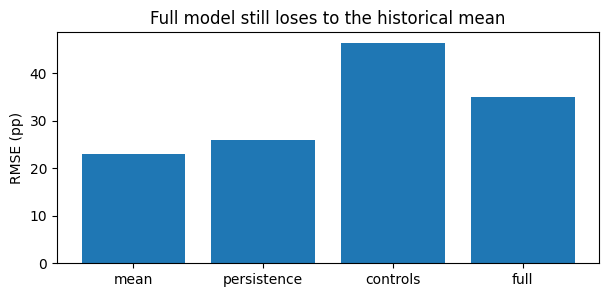

In [19]:
fig,ax=plt.subplots(figsize=(7,3));ax.bar(list(scores),[v['rmse'] for v in scores.values()]);ax.set_ylabel('RMSE (pp)');ax.set_title('Full model still loses to the historical mean');plt.show()

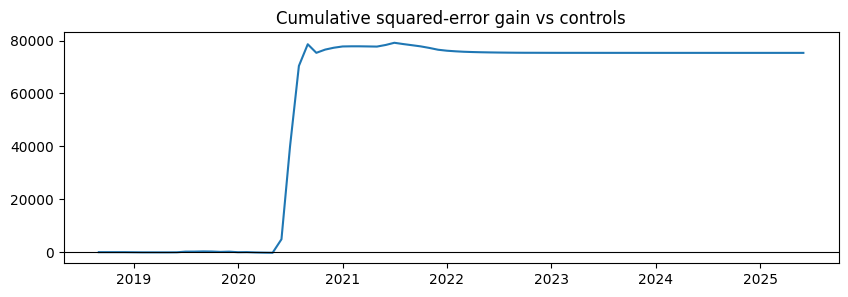

In [20]:
loss_diff=(oos.actual-oos.controls)**2-(oos.actual-oos.full)**2
fig,ax=plt.subplots(figsize=(10,3));ax.plot(oos.index,loss_diff.cumsum().to_numpy());ax.axhline(0,color='black',lw=.8);ax.set_title('Cumulative squared-error gain vs controls');plt.show()

## 10. Robustness & Placebos

- **1,000 block-shuffle refits:** the observed control-minus-full RMSE difference is at an exploratory upper-tail fraction **0.022** when the travel-gap sequence is permuted in 12-month blocks. This is **not** a valid exact permutation p-value: block boundaries, historical revisions, autocorrelation and model selection remain.
- **2,000 moving-block bootstrap draws:** the 95% percentile interval for control-minus-full RMSE is **[-1.963, 23.110] pp**, crossing zero.
- **1,000 exposure perturbations:** the observed fraction with positive improvement over controls is **1.000**, but all such models still require comparison with the historical mean and independent PIT data.
- **Ablation and negative control:** using air YoY alone, a stale 12-month travel gap, alternative horizons (1 and 6 months) and longer BTS reporting delays (5 and 6 months) do not establish stable superiority. Leave-one-year-out is reported separately; deleting 2020 changes the sign of the primary improvement.

In [21]:
delta=scores['controls']['rmse']-scores['full']['rmse']
print('Control-minus-factor RMSE improvement:',round(delta,3),'pp; factor-minus-mean RMSE:',round(scores['full']['rmse']-scores['mean']['rmse'],3),'pp')
print('Exploratory 12-month block-shuffle tail fraction:',round((1+(placebo>=delta).sum())/(1+len(placebo)),4))

Control-minus-factor RMSE improvement: 11.298 pp; factor-minus-mean RMSE: 12.078 pp
Exploratory 12-month block-shuffle tail fraction: 0.022


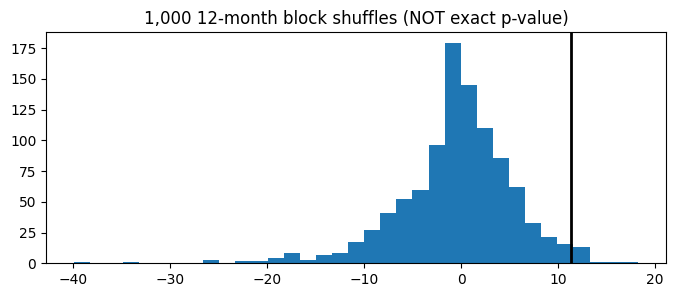

In [22]:
fig,ax=plt.subplots(figsize=(8,3));ax.hist(placebo,bins=35);ax.axvline(delta,color='black',lw=2);ax.set_title('1,000 12-month block shuffles (NOT exact p-value)');plt.show()

Moving-block bootstrap 95% interval: [-1.962681   23.11039326]


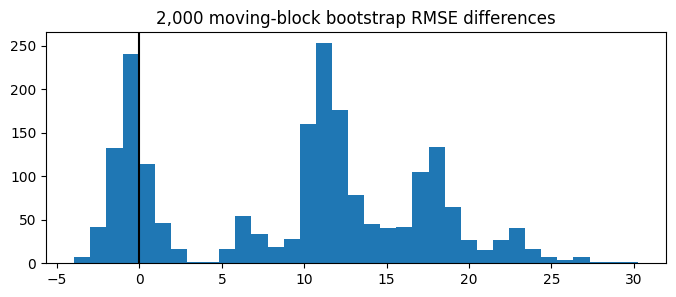

In [23]:
print('Moving-block bootstrap 95% interval:',np.quantile(boot,[.025,.975]))
fig,ax=plt.subplots(figsize=(8,3));ax.hist(boot,bins=35);ax.axvline(0,color='black');ax.set_title('2,000 moving-block bootstrap RMSE differences');plt.show()

## 11. Regime Sensitivity

The 2020 air-travel collapse and subsequent reopening are exceptionally large shocks; they can induce strong in-sample association while destroying stable predictive relationships. In the primary OOS period, excluding 2020 changes the sign of the control-minus-factor RMSE improvement. After 2022, the gap model's RMSE is **2.695 pp**, versus **1.053 pp** for the mean; it does not win even in the calmer period. These are descriptive regime slices selected after seeing data, not independent confirmatory tests.

In [24]:
regimes={k:v for k,v in report['robustness'].items() if k in ('pre_2020','pandemic_2020_2022','post_2022')}
display(pd.DataFrame([{'regime':k,'n':v['n'],'mean_RMSE':v['scores']['mean']['rmse'],'full_RMSE':v['scores']['full']['rmse']} for k,v in regimes.items()]).round(3))

,regime,n,mean_RMSE,full_RMSE
0,pre_2020,18,41.165,39.303
1,pandemic_2020_2022,34,19.254,46.181
2,post_2022,30,1.053,2.695


,excluded_year,n,delta_rmse
0,2018,78,11.585
1,2019,70,13.546
2,2020,70,-0.550
3,2021,70,12.710
4,2022,70,12.575
5,2023,70,12.240
6,2024,70,12.229
7,2025,76,11.736


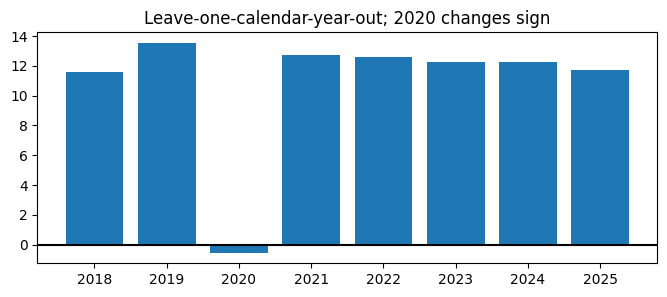

In [25]:
loyo=pd.DataFrame(report['leave_one_year_out']);display(loyo.round(3))
fig,ax=plt.subplots(figsize=(8,3));ax.bar(loyo.excluded_year.astype(str),loyo.delta_rmse);ax.axhline(0,color='black');ax.set_title('Leave-one-calendar-year-out; 2020 changes sign');plt.show()

## 12. Bias Audit & Verdict

**Publication leakage:** unresolved BTS/BLS historical release vintages. **Survivorship:** sector aggregate series avoid listed-company survivorship but omit firm closures and chain composition. **Selection:** only one candidate industry/factor was evaluated in this run; the broader automated research program tests many hypotheses, so multiplicity remains. **Overlap:** 3-month-forward annual growth targets overlap strongly across monthly origins, reducing effective sample size. **Regime instability:** COVID-19 dominates errors. **Economic mismatch:** air miles mix trip purposes and geography, while hotel staffing depends on labor productivity. **Trading:** no stock universe, dividends, delistings, borrow costs, slippage, fees or capacity were tested.

**VERDICT — REPRODUCED RETROSPECTIVE MACRO FALSIFICATION, NOT A VALIDATED FACTOR.** The challenger improves a weak control but fails the historical-mean benchmark, confidence intervals include zero, 2020 drives the gain and historical PIT is unavailable. There is **no investable equity alpha claim**.

In [26]:
audit=pd.DataFrame({'risk':['BTS release vintage','BLS revisions','Overlapping targets','Pandemic regime','No security returns','Source transcription'],
'status':['UNKNOWN','UNKNOWN','PRESENT','HIGH','NOT TESTED','SPOT-CHECKED ONLY']})
display(audit)

,risk,status
0,BTS release vintage,UNKNOWN
1,BLS revisions,UNKNOWN
2,Overlapping targets,PRESENT
3,Pandemic regime,HIGH
4,No security returns,NOT TESTED
5,Source transcription,SPOT-CHECKED ONLY


In [27]:
print('VERDICT: Negative macro forecast result. Fails mean baseline, bootstrap includes zero, 2020 dependence, no PIT and no equity alpha.')

VERDICT: Negative macro forecast result. Fails mean baseline, bootstrap includes zero, 2020 dependence, no PIT and no equity alpha.


## 13. Reproduction

From a clean checkout, in this study directory: `python -m pip install -r requirements.txt`, then `OPENBLAS_NUM_THREADS=1 python run_analysis.py`, `OPENBLAS_NUM_THREADS=1 PYTHONPATH=. pytest -q tests`, and `OPENBLAS_NUM_THREADS=1 jupyter nbconvert --to notebook --execute research.ipynb --output /tmp/air-hotel-reexecuted.ipynb`. For the full repository, run `python scripts/validate_studies.py` at the repository root. The frozen source file checksum is **`98ad34cabef652c021869fcfa74515a322272ddfb53c3e84dcfa65a5d9af5cc0`** (SHA-256). This reproducibility does **not** certify that the manually transcribed values match all official source rows or historical vintages.

In [28]:
snapshot=json.loads(Path('results/metrics.json').read_text())
assert np.isclose(snapshot['scores']['full']['rmse'],scores['full']['rmse'])
assert np.isclose(snapshot['delta_rmse_controls_minus_full'],delta)
assert snapshot['source_sha256']==hashlib.sha256(Path('data/fred_bts_bls_frozen_2026-10-26.csv').read_bytes()).hexdigest()
print('Frozen source checksum and fresh metric reproduction agree')

Frozen source checksum and fresh metric reproduction agree


In [29]:
files=list(Path('figures').glob('*.png'))
print('Computed figures committed separately:',len(files))
assert len(files)>=3

Computed figures committed separately: 9


## 14. Next-Stage Protocol

Before testing investment alpha, acquire historical BTS T-100 release-date snapshots and archived CES vintage records; independently reconcile all monthly source observations against original agency bulk files. Replace employment with independent hotel occupancy/RevPAR and chain-level room nights; map dated company property geography and revenue exposure; freeze an ex-ante hotel stock universe and dividend-adjusted total returns. Then pre-register a monthly formation rule with data availability, lagged fundamental filings, transaction-cost-aware holdout and multiple-testing correction. If these datasets cannot be obtained, retain the result as a macro falsification only.

In [30]:
display(pd.DataFrame({'next_dataset':['BTS original T-100 releases','BLS original vintage CES','Hotel occupancy / RevPAR','Dated issuer fundamentals','Historical adjusted equity returns'],
'available_in_this_study':['NO']*5,'required_for':['PIT demand','PIT payroll','Independent lodging outcome','Firm mapping','Investable alpha']*1}))

,next_dataset,available_in_this_study,required_for
0,BTS original T-100 releases,NO,PIT demand
1,BLS original vintage CES,NO,PIT payroll
2,Hotel occupancy / RevPAR,NO,Independent lodging outcome
3,Dated issuer fundamentals,NO,Firm mapping
4,Historical adjusted equity returns,NO,Investable alpha


In [31]:
print('Pre-register next formation, release-lag and holdout before adding securities data; avoid post-hoc winner selection')

Pre-register next formation, release-lag and holdout before adding securities data; avoid post-hoc winner selection


## 15. Sources & Artifacts

- Primary sources: [BTS air revenue passenger miles](https://fred.stlouisfed.org/data/AIRRPMTSID11), [BLS accommodation payrolls](https://fred.stlouisfed.org/data/CES7072100001), [BLS food services payrolls](https://fred.stlouisfed.org/data/CES7072200001). All accessed **2026-10-26**.
- Provenance: `data/source_register.csv`, `data/transcription_qa.md`, `build_frozen_inputs.py`, `data/fred_bts_bls_frozen_2026-10-26.csv`, `data/exposure_map.csv`.
- Analysis: `run_analysis.py`, `research.ipynb`, `requirements.txt`, `tests/test_hospitality.py`.
- Computed evidence: `data/derived_formation_panel.csv`, `results/metrics.json`, `results/scorecard.csv`, `results/walk_forward_oos.csv`, `results/block_placebo_null.csv`, `results/bootstrap_deltas.csv`, `results/exposure_sensitivity.csv`, `results/leave_one_year_out.csv`, `results/run_log.txt` and **nine** `figures/*.png` files.

In [32]:
display(source[['publisher','series_id','source_url','collection_date']])

,publisher,series_id,source_url,collection_date
0,U.S. Bureau of Transportation Statistics,AIRRPMTSID11,https://fred.stlouisfed.org/data/AIRRPMTSID11,2026-10-26
1,U.S. Bureau of Labor Statistics,CES7072100001,https://fred.stlouisfed.org/data/CES7072100001,2026-10-26
2,U.S. Bureau of Labor Statistics,CES7072200001,https://fred.stlouisfed.org/data/CES7072200001,2026-10-26


In [33]:
print('Raw rows',len(raw),'OOS',len(oos),'figures',len(files),'notebook calculations executed')
print('NO point-in-time / NO company return alpha / NO transaction-cost-aware backtest')

Raw rows 153 OOS 82 figures 9 notebook calculations executed
NO point-in-time / NO company return alpha / NO transaction-cost-aware backtest
